# Лабораторна 10. Завдання 2 — аугментація і тонке налаштування на наборі коні-люди

Курс «Глибокі нейронні мережі». Набір *Horse or Human*: 1027 навчальних і 256
перевірочних зображень 300×300.

Ноутбук продовжує Завдання 1 (перенесення навчання з InceptionV3, зріз по
`mixed7`, голова `Dense(1024) → Dropout(0.2) → Dense(1, sigmoid)`) і відповідає
на три питання умови.

| Пункт | Питання | Як перевіряється |
|---|---|---|
| **2** | як впливає роздільна здатність 150→300 | `base_150` проти `base_300` |
| **3** | як впливає аугментація | `base_150` проти `aug_150` |
| **4** | як впливає донавчання одного блоку | `aug_150` проти `aug_ft_150` |

Чотири конфігурації підібрані так, щоб **кожна пара відрізнялася рівно одним
чинником**. Інакше різницю в результатах не було б чому приписати: якби
аугментація й роздільна здатність змінювалися разом, не можна було б сказати,
що саме дало приріст.

Усі чотири моделі перевіряються на **тих самих 12 власних зображеннях**, яких
немає ні в навчальному, ні в перевірочному наборі.

Середовище, шляхи, перевірка GPU. Якщо список GPU порожній — Середовище виконання → Змінити тип → ГП T4, і перезапустити клітинку.

In [1]:
import json
import os
import shutil
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print('TensorFlow', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
if IN_COLAB and not tf.config.list_physical_devices('GPU'):
    print('\n!! GPU НЕ УВІМКНЕНО. Середовище виконання -> Змінити тип -> ГП T4,\n'
          '   інакше навчання йтиме в десятки разів довше.')

LAB_ROOT = Path('/content') if IN_COLAB else Path.cwd().parent
RESULTS = LAB_ROOT / 'results'
(RESULTS / 'raw').mkdir(parents=True, exist_ok=True)

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print('Результати:', RESULTS)

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Результати: /content/results


Набір коні-люди — той самий, що завантажує базовий ноутбук Завдання 1.

In [2]:
# Той самий набір коні-люди, що в базовому ноутбуці Завдання 1.
if IN_COLAB:
    !wget -q -P /content/ https://storage.googleapis.com/learning-datasets/horse-or-human.zip
    !wget -q -P /content/ https://storage.googleapis.com/learning-datasets/validation-horse-or-human.zip
    with zipfile.ZipFile('/content/horse-or-human.zip') as z:
        z.extractall('/tmp/training')
    with zipfile.ZipFile('/content/validation-horse-or-human.zip') as z:
        z.extractall('/tmp/validation')
    TRAIN_DIR, VAL_DIR = '/tmp/training', '/tmp/validation'
else:
    # Локально набір уже розпакований у лабораторній 7.
    TRAIN_DIR = str(LAB_ROOT.parent / 'lab7' / 'data' / 'horse-or-human')
    VAL_DIR = str(LAB_ROOT.parent / 'lab7' / 'data' / 'validation-horse-or-human')

for name, d in (('навчальний', TRAIN_DIR), ('перевірочний', VAL_DIR)):
    counts = {sub: len(os.listdir(os.path.join(d, sub)))
              for sub in sorted(os.listdir(d)) if os.path.isdir(os.path.join(d, sub))}
    print(f'{name}: {counts}, разом {sum(counts.values())}')

навчальний: {'horses': 500, 'humans': 527}, разом 1027
перевірочний: {'horses': 128, 'humans': 128}, разом 256


Ваги InceptionV3 без верхнього класифікатора.

In [3]:
# Ваги InceptionV3 без верхнього класифікатора.
#
# Базовий ноутбук Завдання 1 тягне їх через wget з бакета mledu-datasets, але
# той більше не відкритий для анонімних запитів (403). Keras завантажує той
# самий файл notop зі свого дзеркала й кешує в ~/.keras/models, тому просто
# просимо weights='imagenet'.
_probe = InceptionV3(input_shape=(150, 150, 3), include_top=False, weights='imagenet')
print('ваги ImageNet готові, параметрів у базі:', f'{_probe.count_params():,}')
del _probe

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
ваги ImageNet готові, параметрів у базі: 21,802,784


**Пункт 2.** Власні тестові зображення.

12 фото з Wikimedia Commons — 6 коней і 6 людей, яких немає в жодному з наборів.
Серед них навмисні «обманки», підібрані під відомі слабкості цього набору даних:
мультяшний і іграшковий кінь (навчальний набір складається з рендерів, не фото),
людина з крилами, людина зі спини в довгій сукні (силует, схожий на чотириноге),
і кадр, де є і кінь, і людина одночасно.

In [4]:
# Власні тестові зображення: 6 коней і 6 людей з Wikimedia Commons,
# яких немає ні в навчальному, ні в перевірочному наборі. Серед них навмисні
# «обманки»: мультяшний кінь, іграшковий кінь, людина з крилами, людина зі
# спини в довгій сукні, кадр, де є і кінь, і людина.
MY_IMAGES = Path('/content/my_images') if IN_COLAB else LAB_ROOT / 'my_images'

if IN_COLAB and not MY_IMAGES.exists():
    from google.colab import drive

    drive.mount('/content/drive')
    src = Path('/content/drive/MyDrive/dl_lab10/my_images.zip')
    if not src.exists():
        raise FileNotFoundError(f'немає {src} — залийте my_images.zip у MyDrive/dl_lab10/')
    with zipfile.ZipFile(src) as z:
        z.extractall(MY_IMAGES)

OWN_DIR = MY_IMAGES / 'horses_humans'
paths = sorted(OWN_DIR.glob('*.jpg'))
print(OWN_DIR, '->', len(paths), 'зображень')
for p in paths:
    print('  ', p.name)

Mounted at /content/drive
/content/my_images/horses_humans -> 12 зображень
   both_person_and_horse.jpg
   horse_cartoon.jpg
   horse_legs_in_grass.jpg
   horse_plain.jpg
   horse_toy.jpg
   horse_white_grass.jpg
   human_angel_wings.jpg
   human_hat.jpg
   human_long_dress_back.jpg
   human_long_hair.jpg
   human_plain_1.jpg
   human_plain_2.jpg


Стенд: побудова генераторів і моделі. Відрізняються лише параметри.

In [5]:
# Стенд експериментів. Одна функція будує модель, друга — генератори,
# щоб між конфігураціями відрізнялося рівно те, що досліджується.

AUG_PARAMS = dict(rotation_range=40, width_shift_range=0.2, height_shift_range=0.2,
                  shear_range=0.2, zoom_range=0.2, horizontal_flip=True,
                  fill_mode='nearest')


def make_generators(size, augment, batch=32):
    """Генератори. Перевірочний набір не аугментується ніколи — інакше
    валідаційна точність перестане бути чесною оцінкою."""
    train_datagen = ImageDataGenerator(rescale=1./255, **(AUG_PARAMS if augment else {}))
    val_datagen = ImageDataGenerator(rescale=1./255)
    train_gen = train_datagen.flow_from_directory(
        TRAIN_DIR, batch_size=batch, class_mode='binary', target_size=(size, size))
    val_gen = val_datagen.flow_from_directory(
        VAL_DIR, batch_size=batch, class_mode='binary', target_size=(size, size))
    return train_gen, val_gen


def build_model(size, unfreeze_from=None, learning_rate=1e-4):
    """InceptionV3 до mixed7 + голова 1024/Dropout 0.2/sigmoid — як у Завданні 1.

    unfreeze_from: ім'я шару, з якого база розморожується (тонке налаштування).
    None — уся база заморожена.
    """
    base = InceptionV3(input_shape=(size, size, 3), include_top=False,
                       weights='imagenet')
    for layer in base.layers:
        layer.trainable = False

    unfrozen = []
    if unfreeze_from is not None:
        names = [l.name for l in base.layers]
        start = names.index(unfreeze_from)
        for layer in base.layers[start:]:
            # BatchNormalization лишаємо замороженим: його ковзні середні взяті
            # з ImageNet і на 1027 зображеннях перенавчаються в шум.
            if isinstance(layer, layers.BatchNormalization):
                continue
            layer.trainable = True
            unfrozen.append(layer.name)

    last_output = base.get_layer('mixed7').output
    x = layers.Flatten()(last_output)
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(1, activation='sigmoid')(x)
    model = Model(inputs=base.input, outputs=x)
    model.compile(optimizer=RMSprop(learning_rate=learning_rate),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model, unfrozen


class StopAt999(tf.keras.callbacks.Callback):
    """Той самий колбек, що в Завданні 1."""

    def on_epoch_end(self, epoch, logs=None):
        if (logs or {}).get('accuracy', 0) > 0.999:
            print('\nДосягнуто 99.9% точності, тому скасовуємо навчання!')
            self.model.stop_training = True

Розпізнавання власних зображень і малювання сітки.

In [6]:
# Розпізнавання власних зображень. Клас береться з префікса імені файлу;
# генератор дав class_indices {'horses': 0, 'humans': 1}, тож sigmoid > 0.5 —
# це «людина». Нормалізація та сама, що при навчанні: rescale=1./255.
#
# Файл both_* містить і коня, і людину — правильної відповіді для нього немає,
# тому в підрахунку він не враховується (та сама умовність, що в ЛР7).
PREFIX_TO_CLASS = {'horse': 0, 'human': 1, 'both': None}
IDX_TO_NAME = {0: 'кінь', 1: 'людина', None: '—'}


def true_class(path):
    prefix = path.stem.split('_')[0]
    if prefix not in PREFIX_TO_CLASS:
        raise ValueError(f'не розумію клас із імені {path.name}')
    return PREFIX_TO_CLASS[prefix]


def score(records):
    """(вгадано, усього) — зображення без правильної відповіді не рахуються."""
    judged = [r for r in records if r['correct'] is not None]
    return sum(r['correct'] for r in judged), len(judged)


def predict_own(model, size):
    """Повертає список результатів по кожному власному зображенню."""
    batch = np.vstack([
        np.expand_dims(img_to_array(load_img(p, target_size=(size, size))) / 255.0, 0)
        for p in paths
    ])
    probs = model.predict(batch, verbose=0).ravel()
    out = []
    for p, prob in zip(paths, probs):
        pred = int(prob > 0.5)
        actual = true_class(p)
        out.append({'file': p.name, 'prob_human': float(prob),
                    'predicted': IDX_TO_NAME[pred], 'actual': IDX_TO_NAME[actual],
                    'correct': None if actual is None else pred == actual})
    return out


def show_predictions(records, size, title, fname):
    cols = 4
    rows = (len(records) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, r in zip(axes, records):
        prob = r['prob_human']
        conf = prob if r['predicted'] == 'людина' else 1 - prob
        if r['correct'] is None:
            mark, colour = '(не рахується)', 'dimgray'
        elif r['correct']:
            mark, colour = '+', 'green'
        else:
            mark, colour = 'ПОМИЛКА', 'crimson'
        ax.imshow(load_img(OWN_DIR / r['file'], target_size=(size, size)))
        ax.set_title(f"{Path(r['file']).stem}\n{r['predicted']} {conf:.0%} {mark}",
                     fontsize=8, color=colour)
        ax.axis('off')
    for ax in axes[len(records):]:
        ax.axis('off')
    correct, judged = score(records)
    fig.suptitle(f'{title}: {correct} з {judged}', fontsize=13)
    plt.tight_layout()
    plt.savefig(RESULTS / fname, dpi=110, bbox_inches='tight')
    plt.show()

Чотири конфігурації.

In [7]:
# Чотири конфігурації. Вони підібрані так, щоб кожна пара відрізнялася
# рівно одним чинником — інакше різницю в результатах не було б чому приписати.
#
#   base_150  -> aug_150     : вплив аугментації          (пункт 3)
#   base_150  -> base_300    : вплив роздільної здатності (пункт 2)
#   aug_150   -> aug_ft_150  : вплив донавчання           (пункт 4)
#
# unfreeze_from='mixed6' розморожує один додатковий inception-блок перед mixed7.
#
# У base_300 батч менший (16 замість 32). Причина — у розмірі моделі: при
# вході 300x300 карта ознак після mixed7 має розмір 17x17 замість 7x7, тож
# Flatten дає вектор у 5.9 раза довший, і шар Dense(1024) після нього розростається
# з 38.5 до 227 млн параметрів. Сама лише його матриця важить 867 МБ, і при
# батчі 32 до цього додається забагато пам'яті під активації.
CONFIGS = [
    {'name': 'base_150', 'title': 'TL, 150x150, без аугментації', 'size': 150,
     'augment': False, 'unfreeze_from': None, 'lr': 1e-4, 'epochs': 20, 'batch': 32},
    {'name': 'aug_150', 'title': 'TL + аугментація, 150x150', 'size': 150,
     'augment': True, 'unfreeze_from': None, 'lr': 1e-4, 'epochs': 20, 'batch': 32},
    {'name': 'base_300', 'title': 'TL, 300x300, без аугментації', 'size': 300,
     'augment': False, 'unfreeze_from': None, 'lr': 1e-4, 'epochs': 20, 'batch': 16},
    {'name': 'aug_ft_150', 'title': 'TL + аугментація + донавчання з mixed6', 'size': 150,
     'augment': True, 'unfreeze_from': 'mixed6', 'lr': 1e-5, 'epochs': 20, 'batch': 32},
]

for c in CONFIGS:
    print(f"{c['name']:<12} {c['title']}")

base_150     TL, 150x150, без аугментації
aug_150      TL + аугментація, 150x150
base_300     TL, 300x300, без аугментації
aug_ft_150   TL + аугментація + донавчання з mixed6


Прогін. Найдовша клітинка: чотири навчання поспіль.

`base_300` помітно повільніший за решту — при вході 300×300 карта ознак після
`mixed7` має розмір 17×17 замість 7×7, тож `Flatten` дає у 5.9 раза більший
вектор, і шар `Dense(1024)` після нього розростається з 38.5 до 227 млн
параметрів.

In [8]:
# Прогін усіх конфігурацій. Найдовша клітинка ноутбука.
runs = {}

for cfg in CONFIGS:
    print('\n' + '=' * 72)
    print(cfg['title'])
    print('=' * 72)

    tf.keras.utils.set_random_seed(SEED)
    train_gen, val_gen = make_generators(cfg['size'], cfg['augment'], cfg['batch'])
    model, unfrozen = build_model(cfg['size'], cfg['unfreeze_from'], cfg['lr'])

    total = int(model.count_params())
    trainable = int(sum(w.shape.num_elements() for w in model.trainable_weights))
    print(f"параметрів: {total:,}, навчаних: {trainable:,}, "
          f"розморожено шарів бази: {len(unfrozen)}, батч: {cfg['batch']}")

    t0 = time.time()
    try:
        history = model.fit(train_gen, validation_data=val_gen, epochs=cfg['epochs'],
                            verbose=2, callbacks=[StopAt999()])
    except (tf.errors.ResourceExhaustedError, MemoryError) as e:
        # На цю гілку можна потрапити лише з base_300: 227 млн параметрів.
        # Сам факт, що конфігурація не влазить у пам'ять, — теж відповідь на
        # питання пункту 2 про вплив роздільної здатності, тож записуємо її.
        print(f'\nНЕ ВИСТАЧИЛО ПАМ`ЯТІ: {type(e).__name__}')
        print('Зменште batch у цій конфігурації або візьміть GPU з більшою пам`яттю.')
        runs[cfg['name']] = {
            **{k: cfg[k] for k in ('name', 'title', 'size', 'augment', 'lr', 'epochs')},
            'unfreeze_from': cfg['unfreeze_from'], 'unfrozen_layers': len(unfrozen),
            'total_params': total, 'trainable_params': trainable,
            'out_of_memory': True,
        }
        del model
        tf.keras.backend.clear_session()
        continue
    elapsed = time.time() - t0

    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    own = predict_own(model, cfg['size'])
    own_correct, own_judged = score(own)

    runs[cfg['name']] = {
        **{k: cfg[k] for k in ('name', 'title', 'size', 'augment', 'lr', 'epochs')},
        'unfreeze_from': cfg['unfreeze_from'],
        'unfrozen_layers': len(unfrozen),
        'total_params': total,
        'trainable_params': trainable,
        'epochs_run': len(acc),
        'final_train_accuracy': float(acc[-1]),
        'final_val_accuracy': float(val_acc[-1]),
        'best_val_accuracy': float(max(val_acc)),
        'overfit_gap': float(acc[-1] - val_acc[-1]),
        'train_time_sec': round(elapsed, 1),
        'history': {k: [float(x) for x in v] for k, v in history.history.items()},
        'own_images': own,
        'own_correct': own_correct,
        'own_total': own_judged,
    }

    print(f"\nепох: {len(acc)}, час: {elapsed / 60:.1f} хв, "
          f"val accuracy: {val_acc[-1]:.4f}, "
          f"власні зображення: {own_correct}/{own_judged}")

    model.save(RESULTS / f"task2_{cfg['name']}.keras")
    del model
    tf.keras.backend.clear_session()

ok_runs = {k: r for k, r in runs.items() if not r.get('out_of_memory')}
print(f'\nПройдено конфігурацій: {len(ok_runs)} з {len(CONFIGS)}')
for _k, _r in runs.items():
    if _r.get('out_of_memory'):
        print(f'  {_k}: не влізла в пам`ять ({_r["total_params"]:,} параметрів)')


TL, 150x150, без аугментації
Found 1027 images belonging to 2 classes.
Found 256 images belonging to 2 classes.
параметрів: 47,512,481, навчаних: 38,537,217, розморожено шарів бази: 0, батч: 32
Epoch 1/20
33/33 - 40s - 1s/step - accuracy: 0.9796 - loss: 0.0365 - val_accuracy: 0.9883 - val_loss: 0.0217
Epoch 2/20

Досягнуто 99.9% точності, тому скасовуємо навчання!
33/33 - 6s - 192ms/step - accuracy: 1.0000 - loss: 7.5120e-04 - val_accuracy: 0.9883 - val_loss: 0.0213

епох: 2, час: 0.8 хв, val accuracy: 0.9883, власні зображення: 9/11

TL + аугментація, 150x150
Found 1027 images belonging to 2 classes.
Found 256 images belonging to 2 classes.
параметрів: 47,512,481, навчаних: 38,537,217, розморожено шарів бази: 0, батч: 32
Epoch 1/20
33/33 - 30s - 919ms/step - accuracy: 0.9309 - loss: 0.1706 - val_accuracy: 0.9883 - val_loss: 0.0280
Epoch 2/20
33/33 - 11s - 328ms/step - accuracy: 0.9873 - loss: 0.0313 - val_accuracy: 0.9844 - val_loss: 0.0444
Epoch 3/20
33/33 - 11s - 322ms/step - accur

Криві навчання. Відстань між суцільною і пунктирною лінією — перенавчання.

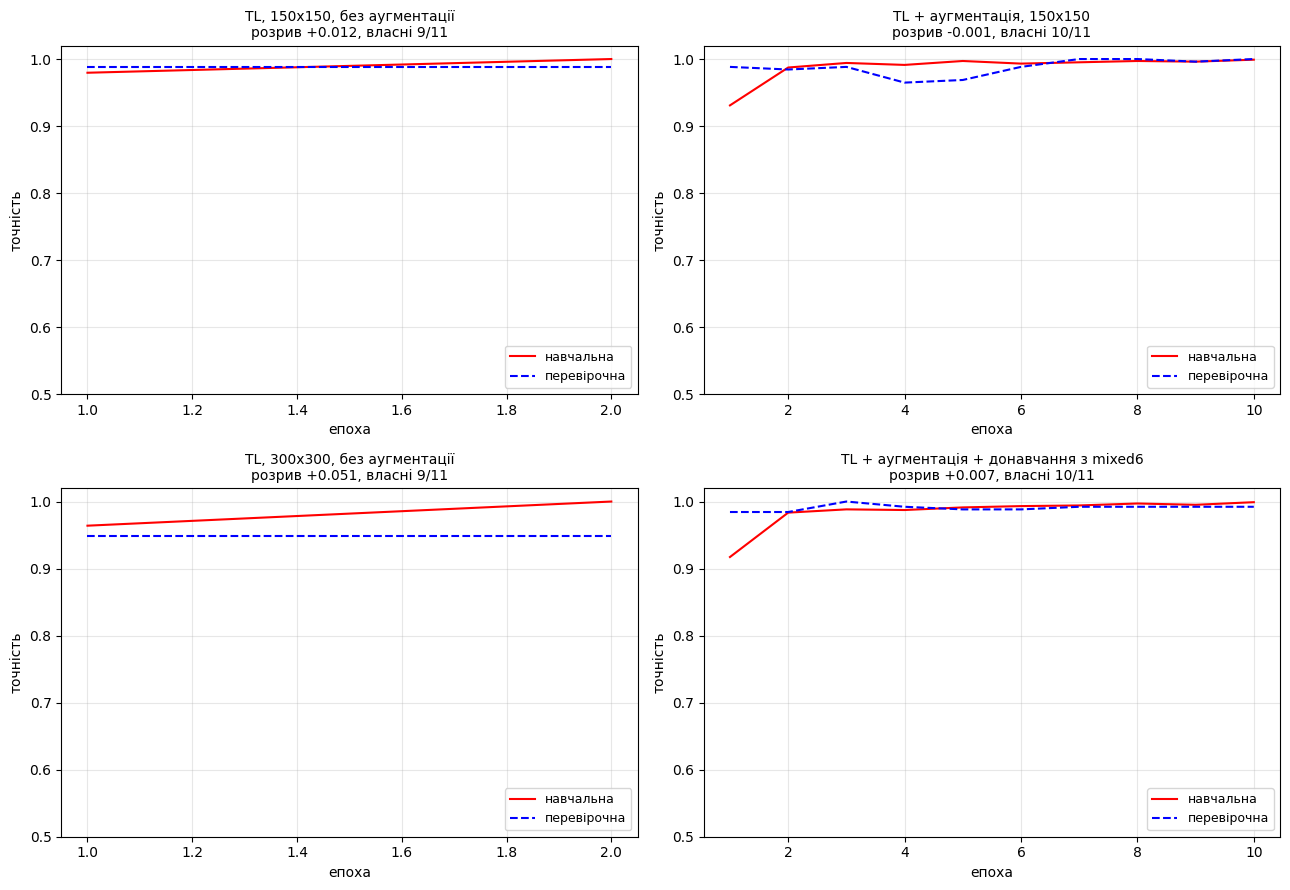

In [9]:
# Криві навчання. Розрив між суцільною і пунктирною лінією — це перенавчання.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax in axes.ravel():
    ax.axis('off')
for ax, (name, r) in zip(axes.ravel(), ok_runs.items()):
    ax.axis('on')
    h = r['history']
    ep = range(1, len(h['accuracy']) + 1)
    ax.plot(ep, h['accuracy'], 'r-', label='навчальна')
    ax.plot(ep, h['val_accuracy'], 'b--', label='перевірочна')
    ax.set_title(f"{r['title']}\nрозрив {r['overfit_gap']:+.3f}, "
                 f"власні {r['own_correct']}/{r['own_total']}", fontsize=10)
    ax.set_xlabel('епоха')
    ax.set_ylabel('точність')
    ax.set_ylim(0.5, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS / 'task2_histories.png', dpi=110, bbox_inches='tight')
plt.show()

**Пункти 2, 3, 4.** Зведена таблиця й прямі відповіді на питання умови.

In [10]:
# Зведена таблиця: кожен рядок — одна конфігурація.
def _num(r, key, fmt):
    """Прочерк для конфігурацій, що не влізли в пам'ять."""
    return format(r[key], fmt) if key in r else '—'


cols = [('конфігурація', lambda r: r['title'][:34]),
        ('вхід', lambda r: f"{r['size']}x{r['size']}"),
        ('аугм.', lambda r: 'так' if r['augment'] else 'ні'),
        ('донавч.', lambda r: r['unfreeze_from'] or 'ні'),
        ('параметрів', lambda r: f"{r['total_params']:,}"),
        ('навчаних', lambda r: f"{r['trainable_params']:,}"),
        ('епох', lambda r: str(r.get('epochs_run', '—'))),
        ('train', lambda r: _num(r, 'final_train_accuracy', '.4f')),
        ('val', lambda r: _num(r, 'final_val_accuracy', '.4f')),
        ('розрив', lambda r: _num(r, 'overfit_gap', '+.3f')),
        ('хв', lambda r: f"{r['train_time_sec'] / 60:.1f}" if 'train_time_sec' in r else '—'),
        ('власні', lambda r: f"{r['own_correct']}/{r['own_total']}"
                             if 'own_correct' in r else '—')]

rows = [[f(r) for _, f in cols] for r in runs.values()]
widths = [max(len(h), *(len(row[i]) for row in rows)) for i, (h, _) in enumerate(cols)]
print(' | '.join(h.ljust(w) for (h, _), w in zip(cols, widths)))
print('-+-'.join('-' * w for w in widths))
for row in rows:
    print(' | '.join(c.ljust(w) for c, w in zip(row, widths)))

print('\nВідповіді на питання завдання:')


def _delta(frm, to, label, extra=''):
    if frm not in runs or to not in runs:
        print(f'  {label}: немає конфігурації '
              f'{frm if frm not in runs else to} — пропускаю')
        return
    a_, b_ = runs[frm], runs[to]
    if 'final_val_accuracy' not in a_ or 'final_val_accuracy' not in b_:
        missing = frm if 'final_val_accuracy' not in a_ else to
        print(f'  {label}: конфігурація {missing} не влізла в пам`ять — '
              f'порівнювати нема з чим, але сам факт є відповіддю '
              f'({runs[missing]["total_params"]:,} параметрів)')
        return
    print(f"  {label}: val {a_['final_val_accuracy']:.4f} -> {b_['final_val_accuracy']:.4f} "
          f"({b_['final_val_accuracy'] - a_['final_val_accuracy']:+.4f}), "
          f"розрив {a_['overfit_gap']:+.3f} -> {b_['overfit_gap']:+.3f}, "
          f"власні {a_['own_correct']} -> {b_['own_correct']}{extra}")


_delta('base_150', 'aug_150', 'пункт 3, аугментація  ')
_extra = ''
if 'base_150' in runs and 'base_300' in runs:
    _extra = (f", параметрів {runs['base_150']['total_params']:,}"
              f" -> {runs['base_300']['total_params']:,}")
_delta('base_150', 'base_300', 'пункт 2, 150 -> 300   ', _extra)
_delta('aug_150', 'aug_ft_150', 'пункт 4, донавчання   ')

конфігурація                       | вхід    | аугм. | донавч. | параметрів  | навчаних    | епох | train  | val    | розрив | хв  | власні
-----------------------------------+---------+-------+---------+-------------+-------------+------+--------+--------+--------+-----+-------
TL, 150x150, без аугментації       | 150x150 | ні    | ні      | 47,512,481  | 38,537,217  | 2    | 1.0000 | 0.9883 | +0.012 | 0.8 | 9/11  
TL + аугментація, 150x150          | 150x150 | так   | ні      | 47,512,481  | 38,537,217  | 10   | 0.9990 | 1.0000 | -0.001 | 2.1 | 10/11 
TL, 300x300, без аугментації       | 300x300 | ні    | ні      | 236,256,161 | 227,280,897 | 2    | 1.0000 | 0.9492 | +0.051 | 0.8 | 9/11  
TL + аугментація + донавчання з mi | 150x150 | так   | mixed6  | 47,512,481  | 40,675,329  | 10   | 0.9990 | 0.9922 | +0.007 | 2.2 | 10/11 

Відповіді на питання завдання:
  пункт 3, аугментація  : val 0.9883 -> 1.0000 (+0.0117), розрив +0.012 -> -0.001, власні 9 -> 10
  пункт 2, 150 -> 300   : val 

**Пункти 2, 3, 4.** Ті самі 12 зображень у всіх конфігураціях.

Ця таблиця цінніша за підсумкову цифру: видно, які саме зображення
обманюють мережу стійко, незалежно від налаштувань, а які виправляються
аугментацією чи донавчанням.

зображення                    TL, 150x150,  TL + аугмент  TL, 300x300,  TL + аугмент
------------------------------------------------------------------------------------
both_person_and_horse.jpg           ? 0.00        ? 0.00        ? 0.00        ? 0.00
horse_cartoon.jpg                   + 0.00        + 0.00        + 0.00        + 0.00
horse_legs_in_grass.jpg             + 0.00        + 0.00        + 0.00        + 0.00
horse_plain.jpg                     + 0.00        + 0.00        + 0.00        + 0.00
horse_toy.jpg                       + 0.32        + 0.00        + 0.07        + 0.00
horse_white_grass.jpg               + 0.00        + 0.00        + 0.00        + 0.00
human_angel_wings.jpg               + 0.98        + 1.00        + 0.96        + 1.00
human_hat.jpg                       + 0.75        + 0.96        + 0.85        + 0.87
human_long_dress_back.jpg           - 0.45        - 0.29        - 0.50        + 0.80
human_long_hair.jpg                 + 0.98        + 1.00        +

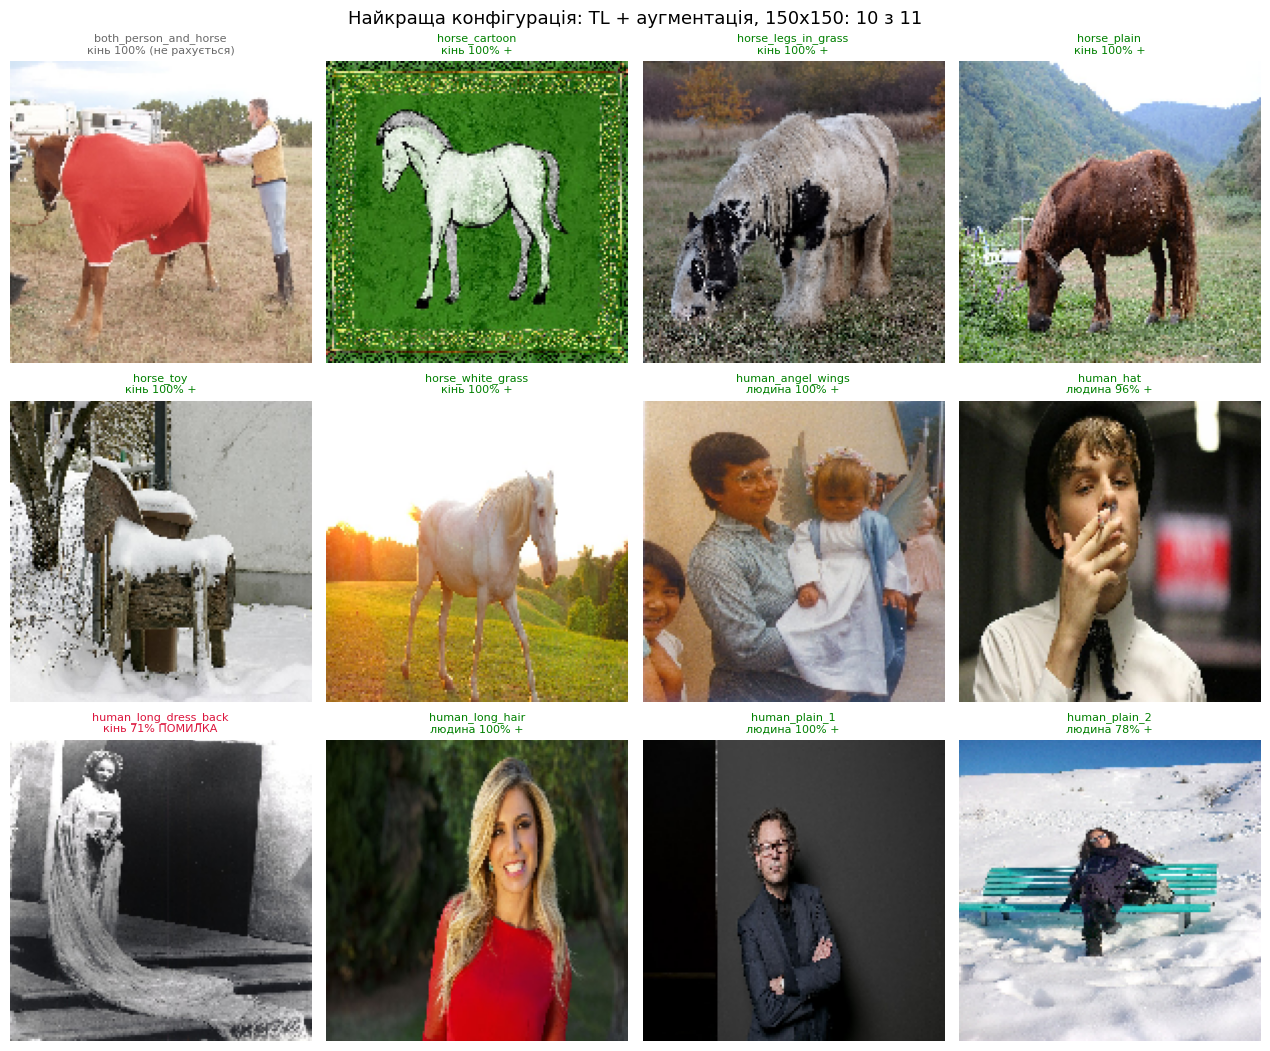

In [11]:
# Ті самі 12 зображень у всіх чотирьох конфігураціях.
# Видно не лише скільки вгадано, а які саме зображення стійко обманюють мережу.
names = [r['title'][:26] for r in ok_runs.values()]
files = [r['file'] for r in next(iter(ok_runs.values()))['own_images']]

print(f"{'зображення':<28} " + ' '.join(f'{n[:12]:>13}' for n in names))
print('-' * (28 + 14 * len(names)))
for i, fname in enumerate(files):
    cells = []
    for r in ok_runs.values():
        rec = r['own_images'][i]
        mark = '?' if rec['correct'] is None else ('+' if rec['correct'] else '-')
        cells.append(f"{mark} {rec['prob_human']:.2f}".rjust(13))
    print(f'{fname:<28} ' + ' '.join(cells))
print('-' * (28 + 14 * len(names)))
print(f"{'ВСЬОГО':<28} " + ' '.join(
    f"{r['own_correct']}/{r['own_total']}".rjust(13) for r in ok_runs.values()))

# Сітка зображень для найкращої конфігурації.
best_name = max(ok_runs, key=lambda k: (ok_runs[k]['own_correct'],
                                        ok_runs[k]['final_val_accuracy']))
best = ok_runs[best_name]
print(f'\nНайкраща за власними зображеннями: {best["title"]}')
show_predictions(best['own_images'], best['size'],
                 f'Найкраща конфігурація: {best["title"]}',
                 'task2_own_images_best.png')

Експорт чисел і зіп з результатами.

Після завантаження покласти зіп у `dl/lab10/results/incoming/`, а сам ноутбук
зберегти через **Файл → Завантажити → Завантажити .ipynb** у `dl/lab10/notebooks/`.

In [12]:
# Експорт усіх чисел + зіп з результатами.
metrics = {'task': 'task2_horses_humans', 'seed': SEED,
           'tensorflow': tf.__version__, 'runs': runs}
out = RESULTS / 'raw' / 'task2.json'
out.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
print('Збережено', out, f'{out.stat().st_size / 1024:.0f} КБ')

if IN_COLAB:
    drive_dir = Path('/content/drive/MyDrive/dl_lab10')
    (drive_dir / 'models').mkdir(parents=True, exist_ok=True)
    (drive_dir / 'results').mkdir(parents=True, exist_ok=True)
    for p in RESULTS.glob('task2_*.keras'):
        shutil.copy(p, drive_dir / 'models' / p.name)
        print('модель ->', drive_dir / 'models' / p.name)

zip_path = (Path('/content') if IN_COLAB else RESULTS) / 'lab10_task2_results.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(RESULTS.rglob('*')):
        if p.is_file() and 'task2' in p.name and p.suffix != '.keras':
            z.write(p, p.relative_to(RESULTS))
print(zip_path, f'{zip_path.stat().st_size / 1e6:.2f} МБ')

if IN_COLAB:
    shutil.copy(zip_path, drive_dir / 'results' / zip_path.name)
    from google.colab import files

    files.download(str(zip_path))

Збережено /content/results/raw/task2.json 15 КБ
модель -> /content/drive/MyDrive/dl_lab10/models/task2_base_300.keras
модель -> /content/drive/MyDrive/dl_lab10/models/task2_base_150.keras
модель -> /content/drive/MyDrive/dl_lab10/models/task2_aug_ft_150.keras
модель -> /content/drive/MyDrive/dl_lab10/models/task2_aug_150.keras
/content/lab10_task2_results.zip 2.09 МБ


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>